# Data Analysis

This notebook will contain descriptive and statistical analysis.

In [1]:
from pathlib import Path
import sys


def find_project_root(start_path: Path) -> Path:
    """Find the repository containing src/ and requirements.txt."""
    for path in [start_path, *start_path.parents]:
        if (path / "src").is_dir() and (path / "requirements.txt").is_file():
            return path
    raise FileNotFoundError(
        "Could not locate the project root containing src/ and requirements.txt."
    )


PROJECT_ROOT = find_project_root(Path.cwd())
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))


In [2]:
from src.paths import RAW_DIR, INTERIM_DIR, PROCESSED_DIR
from src.data_loader import load_data
from src.cleaning.schema import CLEANED_ORDER_ITEMS_SCHEMA
from src.pipeline.contracts.normalizer import normalize_table_types
from src.pipeline.contracts.validator import validate_table_contract
from src.config import RANDOM_SEED


## I. Build the analysis table

##  Setup and parameter



In [3]:
import numpy as np
import pandas as pd

pd.set_option("display.max_columns", None)

TABLES_DIR = PROJECT_ROOT / "outputs" / "tables"
TABLES_DIR.mkdir(parents=True, exist_ok=True)


CORE_COLS = [
    "order_purchase_timestamp",
    "order_approved_at",
    "order_delivered_carrier_date",
    "order_delivered_customer_date",
]
DATE_COLS = CORE_COLS + ["order_estimated_delivery_date"]

SLOT_BINS = [-1, 7, 11, 17, 23]
SLOT_LABELS = [
    "Late night 00-08 (off)",
    "Morning 08-12 (in)",
    "Afternoon 12-18 (in)",
    "Evening 18-24 (off)",
]

PEAK_PERIODS = {
    "Black Friday week": ("2017-11-20", "2017-11-27"),   
}


HOLIDAYS = np.array(
    [f"{y}-{md}" for y in (2016, 2017, 2018) for md in ("01-01", "05-01", "12-25")],
    dtype="datetime64[D]",
)

# ---------- Phân khúc ----------
BULKY_KG = 15                                                
REMOTE_STATES = ["AC", "AM", "AP", "PA", "RO", "RR", "TO"]
SLOW_APPROVAL_DAYS = 1                                       
REGIME_CUTOFF = "2018-04-25"                                 

funnel = []

##  Load dữ liệu đã clean

In [4]:
late = load_data("late_delivery_orders", stage="processed")

# Compatibility for an older saved Parquet that includes two historical QA flags.
# Read it without the exact-column check, drop only those known extra fields,
# then restore and validate the canonical cleaned-data contract below.
items = load_data("cleaned_order_items", stage="processed", validate=False)
expected_columns = list(CLEANED_ORDER_ITEMS_SCHEMA.columns)
legacy_extra_columns = {"missing_category", "missing_product_features"}
missing_columns = set(expected_columns) - set(items.columns)
unexpected_columns = set(items.columns) - set(expected_columns) - legacy_extra_columns
if missing_columns or unexpected_columns:
    raise ValueError(
        "cleaned_order_items has an unsupported schema. "
        f"Missing columns: {sorted(missing_columns)}; "
        f"unexpected columns: {sorted(unexpected_columns)}."
    )

items = items.loc[:, expected_columns].copy()
items = normalize_table_types(
    items, CLEANED_ORDER_ITEMS_SCHEMA, table_name="cleaned_order_items"
)


assert (late["order_status"] == "delivered").all(), "late chứa đơn không phải delivered"

funnel.append({"step": "delivered valid",
               "removed": 0, "remaining": len(late), "note": ""})


Loaded PARQUET from 'C:\Users\trang\PycharmProjects\Intro-to-DataScience-Project\data\processed\late_delivery_orders.parquet'.


## Single-item filtering

In [5]:

assert all(late[c].dt.tz is None for c in DATE_COLS), "A date column is timezone-aware"

miss_core = late[CORE_COLS].isna().any(axis=1)
core = late[~miss_core]
note_missing = ", ".join(f"{int(late[c].isna().sum())} missing {c}" for c in CORE_COLS if late[c].isna().any())

# Negative intervals: same six physical comparisons (and names) as
# 01_exploratory_data_analysis ("Order timestamp sequence").
# Each check is (start, end); an order is flagged when end < start. Equal values are not flagged.
ORDERING_CHECKS = {
    "approved_before_purchase":  ("order_purchase_timestamp",     "order_approved_at"),
    "carrier_before_approval":   ("order_approved_at",            "order_delivered_carrier_date"),
    "customer_before_carrier":   ("order_delivered_carrier_date", "order_delivered_customer_date"),
    "carrier_before_purchase":   ("order_purchase_timestamp",     "order_delivered_carrier_date"),
    "customer_before_approval":  ("order_approved_at",            "order_delivered_customer_date"),
    "customer_before_purchase":  ("order_purchase_timestamp",     "order_delivered_customer_date"),
}
neg_flags = pd.DataFrame({
    name: core[end] < core[start] for name, (start, end) in ORDERING_CHECKS.items()
})
neg_any = neg_flags.any(axis=1)
# Flags overlap, so counts per check do not sum to the number of dropped orders.
note_negative = ", ".join(f"{k}: {int(v)}" for k, v in neg_flags.sum().items() if v)

anomaly_orders = pd.concat([
    late[miss_core].assign(drop_reason="missing_core_timestamp"),
    core[neg_any]
    .join(neg_flags[neg_any].add_prefix("neg_"))
    .assign(drop_reason="negative_interval"),
])
anomaly_orders["flag_carrier_before_purchase"] = (
    anomaly_orders["order_delivered_carrier_date"] < anomaly_orders["order_purchase_timestamp"]
).astype(int)

order_base = core[~neg_any].copy()

funnel.append({"step": "Drop orders missing core timestamps",
               "removed": len(late) - len(core), "remaining": len(core), "note": note_missing})
funnel.append({"step": "Drop orders with negative time intervals",
               "removed": len(core) - len(order_base), "remaining": len(order_base), "note": note_negative})

## Gộp seller, tạo order_df

In [6]:
items["product_weight_g"] = pd.to_numeric(items["product_weight_g"], errors="coerce")

seller_info = (
    items.groupby("order_id")
    .agg(
        seller_id=("seller_id", "first"),
        seller_state=("seller_state", "first"),
        n_sellers=("seller_id", "nunique"),
        product_category=("product_category_name", "first"),
        total_weight_g=("product_weight_g", lambda s: s.sum(min_count=1)),
        shipping_limit_date=("shipping_limit_date", "max"),
    )
    .reset_index()
)

order_df = order_base.merge(seller_info, on="order_id", how="left", validate="one_to_one")

##  Late order

In [7]:
# Compare calendar dates only; ignore hour, minute, and second.
actual_date = order_df["order_delivered_customer_date"].dt.normalize()
estimated_date = order_df["order_estimated_delivery_date"].dt.normalize()

days_over = (actual_date - estimated_date).dt.days
order_df["is_late"] = (days_over > 0).astype(int)
order_df["delay_days"] = days_over.clip(lower=0)

## Time slots across 3 axes

In [8]:
ap = order_df["order_approved_at"]
pu = order_df["order_purchase_timestamp"]

order_df["approve_hour"] = ap.dt.hour
order_df["approve_slot"] = pd.cut(order_df["approve_hour"], SLOT_BINS, labels=SLOT_LABELS)
order_df["hours_type"] = np.where(order_df["approve_hour"].between(8, 17), "In-hours", "Off-hours")

order_df["weekday"] = ap.dt.day_name()
order_df["day_type"] = np.where(ap.dt.dayofweek >= 5, "Weekend", "Weekday")

order_df["month"] = ap.dt.to_period("M").astype(str)
season = pd.Series("Off-peak", index=order_df.index)
for name, (start, end) in PEAK_PERIODS.items():
    season[(ap >= start) & (ap < end)] = name
order_df["season"] = season
order_df["is_peak"] = (season != "Off-peak").astype(int)

order_df["purchase_hour"] = pu.dt.hour
order_df["purchase_slot"] = pd.cut(order_df["purchase_hour"], SLOT_BINS, labels=SLOT_LABELS)

ca = order_df["order_delivered_carrier_date"]
order_df["carrier_hour"] = ca.dt.hour
order_df["carrier_slot"] = pd.cut(order_df["carrier_hour"], SLOT_BINS, labels=SLOT_LABELS)
order_df["carrier_ts_regime"] = np.where(ca < REGIME_CUTOFF, "A: before 25/04/2018", "B: from 25/04/2018")

## Duration of each stage

In [9]:
def working_days(start, end):
    d0 = start.values.astype("datetime64[D]")
    d1 = end.values.astype("datetime64[D]")
    frac0 = ((start - start.dt.normalize()).dt.total_seconds() / 86400).values
    frac1 = ((end - end.dt.normalize()).dt.total_seconds() / 86400).values
    days = (
        np.busday_count(d0, d1, holidays=HOLIDAYS)
        - frac0 * np.is_busday(d0, holidays=HOLIDAYS)
        + frac1 * np.is_busday(d1, holidays=HOLIDAYS)
    )
    return pd.Series(days, index=start.index).clip(lower=0)

cu = order_df["order_delivered_customer_date"]
es = order_df["order_estimated_delivery_date"]

order_df["approval_days"] = (ap - pu).dt.total_seconds() / 86400
order_df["processing_lead_time"] = working_days(ap, ca)
order_df["carrier_transit_time"] = working_days(ca, cu)
order_df["lead_days"] = (cu - pu).dt.total_seconds() / 86400
order_df["estimated_lead_days"] = (es - pu).dt.total_seconds() / 86400
order_df[["approval_days", "processing_lead_time", "carrier_transit_time", "lead_days", "estimated_lead_days"]].describe().round(2)

,approval_days,processing_lead_time,carrier_transit_time,lead_days,estimated_lead_days
count,95082.00,95082.00,95082.00,95082.00,95082.00
mean,0.40,2.03,6.64,12.62,23.74
std,0.80,2.43,6.15,9.57,8.77
min,0.00,0.00,0.00,0.53,2.01
25%,0.01,0.75,3.04,6.81,18.34
50%,0.01,1.30,5.08,10.27,23.24
75%,0.56,2.46,8.29,15.81,28.41
max,30.89,87.76,146.19,209.63,155.14


## Seller delays and market segment shifts

In [10]:
order_df["seller_delay"] = (order_df["order_delivered_carrier_date"] > order_df["shipping_limit_date"]).astype(int)

order_df["same_state"] = (order_df["customer_state"] == order_df["seller_state"]).astype(int)
order_df["route_type"] = np.where(order_df["same_state"] == 1, "Intra-state", "Inter-state")
order_df["route"] = order_df["seller_state"] + ">" + order_df["customer_state"]

order_df["is_multi_seller"] = (order_df["n_sellers"] > 1).astype(int)
order_df["is_bulky"] = (order_df["total_weight_g"] > BULKY_KG * 1000).astype(int)
order_df["is_remote"] = order_df["customer_state"].isin(REMOTE_STATES).astype(int)
order_df["slow_approval"] = (order_df["approval_days"] > SLOW_APPROVAL_DAYS).astype(int)
segment_summary = pd.DataFrame({
    "orders": [
        order_df["seller_delay"].sum(),
        order_df["same_state"].sum(),
        order_df["is_multi_seller"].sum(),
        order_df["is_bulky"].sum(),
        order_df["is_remote"].sum(),
        order_df["slow_approval"].sum(),
    ],
    "share_pct": [
        order_df["seller_delay"].mean() * 100,
        order_df["same_state"].mean() * 100,
        order_df["is_multi_seller"].mean() * 100,
        order_df["is_bulky"].mean() * 100,
        order_df["is_remote"].mean() * 100,
        order_df["slow_approval"].mean() * 100,
    ],
}, index=["seller_delay", "same_state", "is_multi_seller", "is_bulky", "is_remote", "slow_approval"]).round(2)
segment_summary

,orders,share_pct
seller_delay,8688,9.14
same_state,34181,35.95
is_multi_seller,1223,1.29
is_bulky,2614,2.75
is_remote,1776,1.87
slow_approval,15909,16.73


## Save data

In [11]:
interval_cols = ["approval_days", "processing_lead_time", "carrier_transit_time", "lead_days"]
assert (order_df[interval_cols] >= 0).all().all()

funnel_df = pd.DataFrame(funnel)
funnel_df.to_csv(TABLES_DIR / "step1_funnel.csv", index=False)

order_df.to_parquet(PROCESSED_DIR / "order_analysis.parquet", index=False)
anomaly_orders.to_parquet(PROCESSED_DIR / "anomaly_orders.parquet", index=False)
funnel_df


,step,removed,remaining,note
0,delivered valid,0,96447,
1,Drop orders missing core timestamps,15,96432,"14 missing order_approved_at, 1 missing order_..."
2,Drop orders with negative time intervals,1350,95082,"carrier_before_approval: 1350, carrier_before_..."


In [12]:
print("order_df:", order_df.shape, "| anomaly_orders:", anomaly_orders.shape)
print("Late rate (date-based):", round(order_df["is_late"].mean() * 100, 2), "%")
print()
print(order_df["approve_slot"].value_counts().sort_index())
print()
print(order_df["season"].value_counts())
print()
print(order_df["carrier_ts_regime"].value_counts())
print()
print(order_df[["processing_lead_time", "carrier_transit_time"]].agg(["median", "mean"]).round(2))
print()
print("slow_approval:", int(order_df["slow_approval"].sum()), "| is_remote:", int(order_df["is_remote"].sum()))

order_df: (95082, 49) | anomaly_orders: (1365, 25)
Late rate (date-based): 6.85 %

approve_slot
Late night 00-08 (off)    22254
Morning 08-12 (in)        15675
Afternoon 12-18 (in)      30450
Evening 18-24 (off)       26703
Name: count, dtype: int64

season
Off-peak             92366
Black Friday week     2716
Name: count, dtype: int64

carrier_ts_regime
A: before 25/04/2018    68614
B: from 25/04/2018      26468
Name: count, dtype: int64

        processing_lead_time  carrier_transit_time
median                  1.30                  5.08
mean                    2.03                  6.64

slow_approval: 15909 | is_remote: 1776


## II. baseline latency rate

### Route type for multi-seller orders
Orders with several sellers have no single seller state, so they are labelled `Multi-seller` and receive no route.

In [13]:
multi = order_df["n_sellers"] > 1
order_df["route_type"] = np.where(multi, "Multi-seller", order_df["route_type"])
order_df.loc[multi, "route"] = np.nan

### Overall late rate

Late rate with a 95% Wilson confidence interval, compared with the timestamp-based definition.

In [14]:
def wilson_ci(k, n, z=1.96):
    p = k / n
    d = 1 + z**2 / n
    centre = (p + z**2 / (2 * n)) / d
    half = z * np.sqrt(p * (1 - p) / n + z**2 / (4 * n**2)) / d
    return centre - half, centre + half


n, k = len(order_df), int(order_df["is_late"].sum())
lo, hi = wilson_ci(k, n)

print(f"Orders: {n:,} | late: {k:,} | late rate: {k / n:.2%} (95% Wilson CI {lo:.2%} - {hi:.2%})")

Orders: 95,082 | late: 6,509 | late rate: 6.85% (95% Wilson CI 6.69% - 7.01%)


### Delay distribution

Distribution of `delay_days` among late orders.

In [15]:
order_df.loc[order_df["is_late"] == 1, "delay_days"].describe().round(2)

count    6509.00
mean       10.62
std        14.65
min         1.00
25%         3.00
50%         7.00
75%        13.00
max       188.00
Name: delay_days, dtype: float64

### Estimated versus actual lead time

`buffer_days` is the estimated lead time minus the actual lead time. A large positive buffer means the estimated date is wide.

In [16]:
order_df["buffer_days"] = order_df["estimated_lead_days"] - order_df["lead_days"]

lead_cols = ["estimated_lead_days", "lead_days", "buffer_days"]
width = order_df.groupby("is_late")[lead_cols].median().round(2)
width.loc["all"] = order_df[lead_cols].median().round(2)
display(width)

print(f"Orders delivered more than 7 days early: {(order_df['buffer_days'] > 7).mean():.1%}")

,estimated_lead_days,lead_days,buffer_days
is_late,,,
0,23.27,9.86,12.25
1,22.49,31.26,-7.54
all,23.24,10.27,11.59


Orders delivered more than 7 days early: 73.7%


## III. Lifecycle bottleneck diagnosis

### Boolean late flag

In [17]:
order_df["is_late"] = order_df["is_late"].astype(bool)

### Median duration by stage

Median of each stage for on-time and late orders. Processing and carrier stages exclude weekends and the holidays 01/01, 01/05 and 25/12.

In [18]:
import matplotlib.pyplot as plt

STAGES = ["approval_days", "processing_lead_time", "carrier_transit_time"]

stage_cmp = (
    order_df.groupby("is_late")[STAGES + ["lead_days"]].median().T
    .rename(columns={False: "on_time_median", True: "late_median"})
)
stage_cmp["diff_days"] = stage_cmp["late_median"] - stage_cmp["on_time_median"]
stage_cmp["ratio"] = (stage_cmp["late_median"] / stage_cmp["on_time_median"]).round(2)
stage_cmp = stage_cmp.round(2)

### Share of the gap

Each stage's share of the total positive gap between late and on-time orders. Approval uses calendar days and the other two use working days, so the shares show ranking rather than exact percentages.

In [19]:
gap = stage_cmp.loc[STAGES, "diff_days"].clip(lower=0)
stage_cmp.loc[STAGES, "share_of_gap_pct"] = (gap / gap.sum() * 100).round(1)
stage_cmp.to_csv(TABLES_DIR / "step3_stage_comparison.csv")
stage_cmp

is_late,on_time_median,late_median,diff_days,ratio,share_of_gap_pct
approval_days,0.01,0.02,0.00,1.19,0.0
processing_lead_time,1.25,2.09,0.84,1.67,5.9
carrier_transit_time,4.93,18.25,13.33,3.71,94.1
lead_days,9.86,31.26,21.39,3.17,NaN


### Mean, median and P75

Checks that the median comparison is not hiding a heavy tail.

In [20]:
def p75(s):
    return s.quantile(0.75)


order_df.groupby("is_late")[STAGES].agg(["mean", "median", p75]).round(2)

approval_days              processing_lead_time               \
                 mean median   p75                 mean median   p75   
is_late                                                                
False            0.39   0.01  0.55                 1.89   1.25  2.32   
True             0.50   0.02  0.77                 3.98   2.09  4.42   

        carrier_transit_time                
                        mean median    p75  
is_late                                     
False                   5.69   4.93   7.79  
True                   19.63  18.25  24.39

### Stage comparison chart

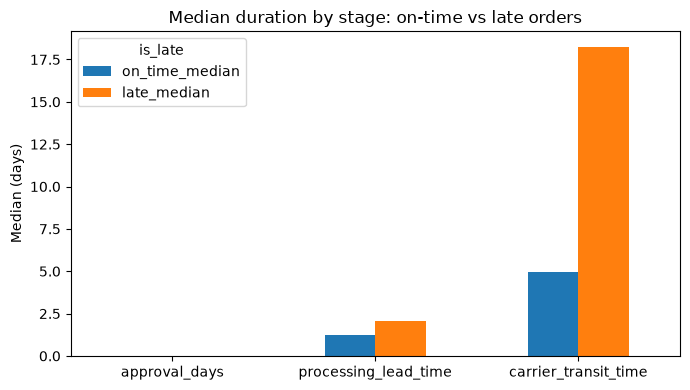

In [21]:
ax = stage_cmp.loc[STAGES, ["on_time_median", "late_median"]].plot.bar(figsize=(7, 4), rot=0)
ax.set_ylabel("Median (days)")
ax.set_title("Median duration by stage: on-time vs late orders")
plt.tight_layout()
plt.show()

## IV. Seller delay vs carrier delay

### Carrier delay threshold

A route's threshold is Q3 + 1.5 × IQR of `carrier_transit_time`. Routes with fewer than 30 orders, and multi-seller orders, use the customer-state threshold.

In [22]:
MIN_ROUTE_ORDERS = 30


def iqr_threshold(s):
    q1, q3 = s.quantile([0.25, 0.75])
    return q3 + 1.5 * (q3 - q1)


route_thr = order_df.groupby("route")["carrier_transit_time"].agg(iqr_threshold)
state_thr = order_df.groupby("customer_state")["carrier_transit_time"].agg(iqr_threshold)
route_cnt = order_df["route"].value_counts()

### Carrier delay flag

An order is flagged when its transit time exceeds its threshold. `threshold_basis` records which threshold was used.

In [23]:
use_route = order_df["route"].map(route_cnt).ge(MIN_ROUTE_ORDERS).fillna(False).astype(bool)

thr_route = pd.to_numeric(order_df["route"].map(route_thr), errors="coerce")
thr_state = pd.to_numeric(order_df["customer_state"].map(state_thr), errors="coerce")

order_df["transit_threshold"] = thr_route.where(use_route, thr_state)
order_df["threshold_basis"] = np.where(use_route, "route", "customer_state")
order_df["carrier_delay"] = (
    order_df["carrier_transit_time"] > order_df["transit_threshold"]
).astype(int)

print(order_df["threshold_basis"].value_counts())
print(f"seller_delay: {order_df['seller_delay'].mean():.2%} | carrier_delay: {order_df['carrier_delay'].mean():.2%}")

threshold_basis
route             91696
customer_state     3386
Name: count, dtype: int64
seller_delay: 9.14% | carrier_delay: 5.60%


### Late rate by delay flag

Late rate of all orders with and without each flag.

In [24]:
pd.DataFrame({
    "seller_delay": order_df.groupby("seller_delay")["is_late"].mean().mul(100).round(2),
    "carrier_delay": order_df.groupby("carrier_delay")["is_late"].mean().mul(100).round(2),
}).rename_axis("flag_value")

,seller_delay,carrier_delay
flag_value,,
0,5.43,3.37
1,20.88,65.49


### Delay-related groups among late orders

Late orders are split into four independent groups: seller only, carrier only, both, and neither.

In [25]:
late_df = order_df[order_df["is_late"]].copy()
sd = late_df["seller_delay"].eq(1)
cd = late_df["carrier_delay"].eq(1)

late_df["cause"] = np.select(
    [sd & ~cd, ~sd & cd, sd & cd],
    ["1. Seller only", "2. Carrier only", "3. Both"],
    default="4. Neither",
)

### Breakdown table

Orders, delay days and shares for each cause group.

In [26]:
cause_summary = late_df.groupby("cause").agg(
    orders=("order_id", "size"),
    median_delay_days=("delay_days", "median"),
    total_delay_days=("delay_days", "sum"),
)
cause_summary["share_orders_pct"] = (cause_summary["orders"] / len(late_df) * 100).round(1)
cause_summary["share_delay_days_pct"] = (
    cause_summary["total_delay_days"] / late_df["delay_days"].sum() * 100
).round(1)

cause_summary.to_csv(TABLES_DIR / "step4_cause_breakdown.csv")
cause_summary.round(2)

,orders,median_delay_days,total_delay_days,share_orders_pct,share_delay_days_pct
cause,,,,,
1. Seller only,1311,5.0,9074,20.1,13.1
2. Carrier only,2985,10.0,43428,45.9,62.8
3. Both,503,12.0,8791,7.7,12.7
4. Neither,1710,4.0,7858,26.3,11.4


### Cause structure chart

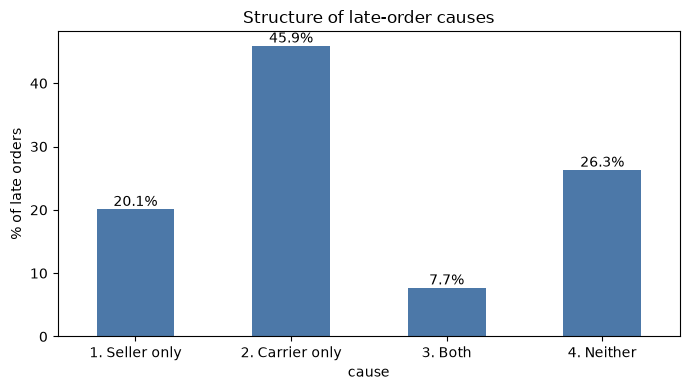

In [27]:
ax = cause_summary["share_orders_pct"].plot.bar(figsize=(7, 4), rot=0, color="#4c78a8")
ax.set_ylabel("% of late orders")
ax.set_title("Structure of late-order causes")
for p in ax.patches:
    ax.annotate(
        f"{p.get_height():.1f}%",
        (p.get_x() + p.get_width() / 2, p.get_height()),
        ha="center",
        va="bottom",
    )
plt.tight_layout()
plt.show()

## V. Time slot analysis on 3 axes

### Late rate by axis

Late rate with a Wilson interval for each time axis, anchored on `order_approved_at`: hour-of-day slot, in/off hours, weekday/weekend and season.

In [28]:
def late_rate_by(col):
    g = order_df.groupby(col, observed=True)["is_late"].agg(orders="size", late="sum")
    g["late_rate_pct"] = (g["late"] / g["orders"] * 100).round(2)
    ci = [wilson_ci(r.late, r.orders) for r in g.itertuples()]
    g["ci_low_pct"] = [round(c[0] * 100, 2) for c in ci]
    g["ci_high_pct"] = [round(c[1] * 100, 2) for c in ci]
    return g


AXES = {
    "Hour of day (slot)": "approve_slot",
    "In/Off hours": "hours_type",
    "Weekday/Weekend": "day_type",
    "Season": "season",
}
axis_tables = {name: late_rate_by(col) for name, col in AXES.items()}

### Axis tables

In [29]:
for name, tbl in axis_tables.items():
    print(name)
    display(tbl)

pd.concat(axis_tables, names=["axis", "value"]).to_csv(TABLES_DIR / "step5_axis_late_rates.csv")

Hour of day (slot)


,orders,late,late_rate_pct,ci_low_pct,ci_high_pct
approve_slot,,,,,
Late night 00-08 (off),22254,1615,7.26,6.92,7.61
Morning 08-12 (in),15675,983,6.27,5.90,6.66
Afternoon 12-18 (in),30450,2085,6.85,6.57,7.14
Evening 18-24 (off),26703,1826,6.84,6.54,7.15


In/Off hours


,orders,late,late_rate_pct,ci_low_pct,ci_high_pct
hours_type,,,,,
In-hours,46125,3068,6.65,6.43,6.88
Off-hours,48957,3441,7.03,6.81,7.26


Weekday/Weekend


,orders,late,late_rate_pct,ci_low_pct,ci_high_pct
day_type,,,,,
Weekday,74533,5181,6.95,6.77,7.14
Weekend,20549,1328,6.46,6.13,6.81


Season


,orders,late,late_rate_pct,ci_low_pct,ci_high_pct
season,,,,,
Black Friday week,2716,450,16.57,15.22,18.01
Off-peak,92366,6059,6.56,6.40,6.72


### Chi-square test and Cramér's V

For each axis, a chi-square test of independence between the axis and `is_late`. Cramér's V measures effect size, where values below 0.1 are negligible.

In [30]:
from scipy.stats import chi2_contingency


def chi2_cramers_v(col):
    ct = pd.crosstab(order_df[col], order_df["is_late"])
    chi2, p, dof, _ = chi2_contingency(ct, correction=False)
    v = np.sqrt(chi2 / (ct.to_numpy().sum() * (min(ct.shape) - 1)))
    return {"axis_column": col, "chi2": round(chi2, 2), "dof": dof, "p_value": p, "cramers_v": round(v, 4)}


stat_tests = pd.DataFrame([chi2_cramers_v(col) for col in AXES.values()])
stat_tests["significant_5pct"] = stat_tests["p_value"] < 0.05
stat_tests["effect_size"] = pd.cut(
    stat_tests["cramers_v"],
    bins=[0, 0.1, 0.3, 0.5, 1],
    labels=["negligible", "small", "medium", "large"],
    include_lowest=True,
)
stat_tests.to_csv(TABLES_DIR / "step5_stat_tests.csv", index=False)
stat_tests

,axis_column,chi2,dof,p_value,cramers_v,significant_5pct,effect_size
0,approve_slot,14.02,3,2.872496e-03,0.0121,True,negligible
1,hours_type,5.30,1,2.136550e-02,0.0075,True,negligible
2,day_type,6.03,1,1.404738e-02,0.0080,True,negligible
3,season,414.46,1,3.923660e-92,0.0660,True,negligible


### Hour × weekday heatmap

Late rate by approval weekday and approval hour. Cells with fewer than 30 orders are left blank.

In [31]:
WEEKDAYS = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]

heat_src = order_df.assign(late_int=order_df["is_late"].astype(int))
heat_rate = heat_src.pivot_table(
    index="weekday", columns="approve_hour", values="late_int", aggfunc="mean"
).reindex(index=WEEKDAYS, columns=range(24)) * 100
heat_count = heat_src.pivot_table(
    index="weekday", columns="approve_hour", values="late_int", aggfunc="size"
).reindex(index=WEEKDAYS, columns=range(24))
heat_rate = heat_rate.where(heat_count >= 30)

### Heatmap plot

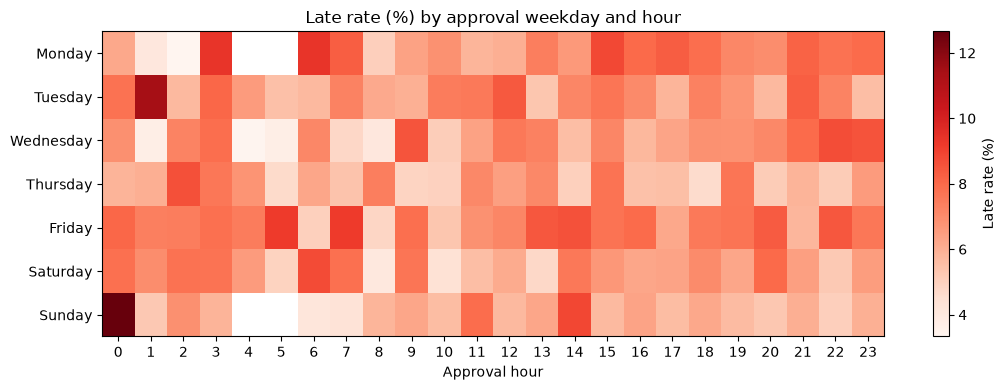

In [32]:
fig, ax = plt.subplots(figsize=(11, 4))
im = ax.imshow(heat_rate.to_numpy(dtype=float), aspect="auto", cmap="Reds")
ax.set_xticks(range(24))
ax.set_xticklabels(range(24))
ax.set_yticks(range(7))
ax.set_yticklabels(WEEKDAYS)
ax.set_xlabel("Approval hour")
ax.set_title("Late rate (%) by approval weekday and hour")
fig.colorbar(im, ax=ax, label="Late rate (%)")
plt.tight_layout()
plt.show()

### Highest-risk slots

Slot with the highest late rate and slot with the most late orders.

In [33]:
slot = axis_tables["Hour of day (slot)"]
print("Highest late rate:", slot["late_rate_pct"].idxmax(), slot["late_rate_pct"].max(), "%")
print("Most late orders:", slot["late"].idxmax(), int(slot["late"].max()), "orders")

Highest late rate: Late night 00-08 (off) 7.26 %
Most late orders: Afternoon 12-18 (in) 2085 orders


### Late rate by weekday

Late rate for each of the 7 approval weekdays with a 95% Wilson interval. `excess_late_orders` is the number of late orders above (positive) or below (negative) what the overall late rate would give for that weekday.

In [34]:
weekday_tbl = late_rate_by("weekday").reindex(WEEKDAYS)
overall_rate = order_df["is_late"].mean()
weekday_tbl["share_of_orders_pct"] = (weekday_tbl["orders"] / len(order_df) * 100).round(1)
weekday_tbl["excess_late_orders"] = (weekday_tbl["late"] - weekday_tbl["orders"] * overall_rate).round(0)
weekday_tbl.to_csv(TABLES_DIR / "step5_weekday_late_rates.csv")
display(weekday_tbl)
pd.DataFrame([chi2_cramers_v("weekday")])

,orders,late,late_rate_pct,ci_low_pct,ci_high_pct,share_of_orders_pct,excess_late_orders
weekday,,,,,,,
Monday,12535,907,7.24,6.80,7.70,13.2,49.0
Tuesday,18181,1262,6.94,6.58,7.32,19.1,17.0
Wednesday,15198,1036,6.82,6.43,7.23,16.0,-4.0
Thursday,14500,927,6.39,6.01,6.80,15.2,-66.0
Friday,14119,1049,7.43,7.01,7.87,14.8,82.0
Saturday,11800,783,6.64,6.20,7.10,12.4,-25.0
Sunday,8749,545,6.23,5.74,6.76,9.2,-54.0


,axis_column,chi2,dof,p_value,cramers_v
0,weekday,21.51,6,0.001485,0.015


### Weekday chart

Bars start at zero so the differences are shown at their true scale. The dashed line is the overall late rate.

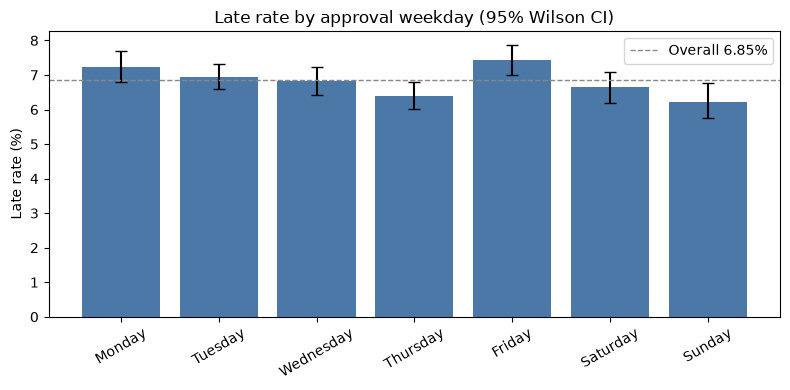

In [35]:
fig, ax = plt.subplots(figsize=(8, 4))
err = [
    weekday_tbl["late_rate_pct"] - weekday_tbl["ci_low_pct"],
    weekday_tbl["ci_high_pct"] - weekday_tbl["late_rate_pct"],
]
ax.bar(weekday_tbl.index, weekday_tbl["late_rate_pct"], yerr=err, capsize=4, color="#4c78a8")
ax.axhline(overall_rate * 100, color="#888888", linestyle="--", linewidth=1, label=f"Overall {overall_rate:.2%}")
ax.set_ylim(bottom=0)
ax.set_ylabel("Late rate (%)")
ax.set_title("Late rate by approval weekday (95% Wilson CI)")
ax.legend()
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

### Slow approval by weekday

Share of orders whose payment approval took more than one day. If this share differs a lot between weekdays, part of the weekday gap is a payment effect and not a weekday effect.

In [36]:
slow_by_weekday = (order_df.groupby("weekday")["slow_approval"].mean().reindex(WEEKDAYS) * 100).round(1)
slow_by_weekday.rename("slow_approval_pct").to_frame()

,slow_approval_pct
weekday,
Monday,9.0
Tuesday,28.8
Wednesday,16.5
Thursday,17.0
Friday,16.3
Saturday,16.6
Sunday,3.8


### Weekday vs weekend with controls

Late rate for weekday and weekend orders in four views:
- `raw`: no control.
- `fast_approval_only` / `slow_approval_only`: only orders in that approval group.
- `month_adjusted`: each month weighted by its number of orders, so the weekday and weekend rates are compared on the same month mix. Months missing one of the two groups are dropped.

In [37]:
late_int = order_df["is_late"].astype(int)

raw = late_int.groupby(order_df["day_type"]).mean() * 100
by_slow = late_int.groupby([order_df["day_type"], order_df["slow_approval"]]).mean().unstack() * 100

by_month = late_int.groupby([order_df["month"], order_df["day_type"]]).mean().unstack().dropna()
month_weight = order_df.groupby("month").size().reindex(by_month.index)
month_adjusted = by_month.mul(month_weight, axis=0).sum() / month_weight.sum() * 100

control_tbl = pd.DataFrame({
    "raw": raw,
    "fast_approval_only": by_slow[0],
    "slow_approval_only": by_slow[1],
    "month_adjusted": month_adjusted,
}).round(2)
control_tbl.to_csv(TABLES_DIR / "step5_weekday_controls.csv")
control_tbl

,raw,fast_approval_only,slow_approval_only,month_adjusted
day_type,,,,
Weekday,6.95,6.59,8.58,7.01
Weekend,6.46,6.28,7.96,6.19


## VI. Operational bottleneck and cut-off time

### Carrier handover hour: peaks by regime

Hour-of-day distribution of `order_delivered_carrier_date`, split into regime A (before 25/04/2018) and regime B (from 25/04/2018) because the recording of handover time changed. A peak hour is an hour with at least 1.5x the average hourly count of its regime; the peaks are read as truck pickup times.

In [38]:
from scipy.stats import chi2_contingency

CUTOFF_PEAK_RATIO = 1.5

hour_counts = pd.crosstab(order_df["carrier_hour"], order_df["carrier_ts_regime"]).reindex(range(24), fill_value=0)
hour_share = hour_counts / hour_counts.sum() * 100
peak_flag = hour_counts.ge(hour_counts.mean() * CUTOFF_PEAK_RATIO)

peak_summary = pd.DataFrame({
    "orders": hour_counts.sum(),
    "modal_hour": hour_counts.idxmax(),
    "peak_hours": [", ".join(f"{h:02d}h" for h in peak_flag.index[peak_flag[c]]) for c in hour_counts],
    "share_in_peak_hours_pct": [round(hour_share.loc[peak_flag[c], c].sum(), 1) for c in hour_counts],
})
peak_summary.to_csv(TABLES_DIR / "step6_carrier_hour_peaks.csv")
peak_summary

,orders,modal_hour,peak_hours,share_in_peak_hours_pct
carrier_ts_regime,,,,
A: before 25/04/2018,68614,19,"15h, 16h, 17h, 18h, 19h, 20h, 21h, 22h",64.6
B: from 25/04/2018,26468,14,"11h, 12h, 13h, 14h, 15h",75.3


### Cut-off time chart

Histogram of the handover hour for each regime. Red bars are the peak hours.

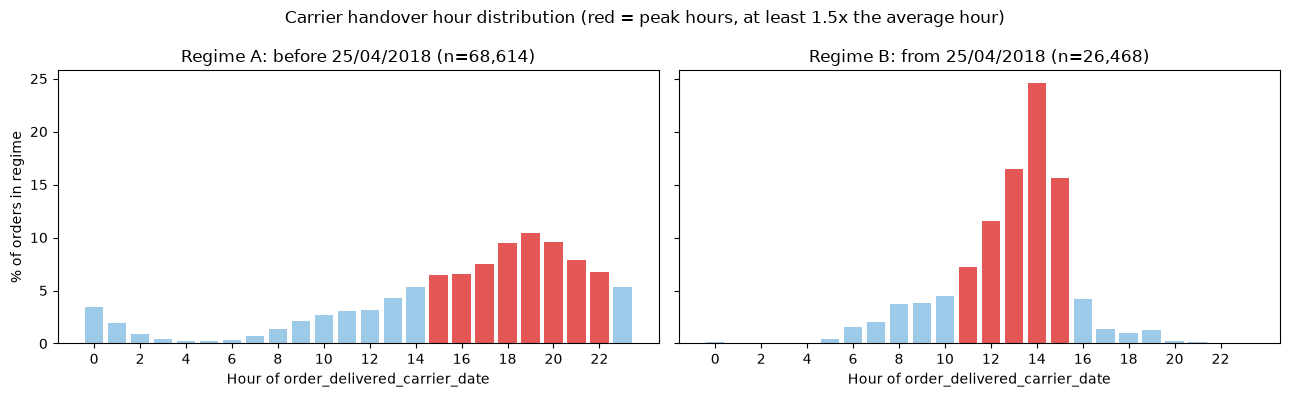

In [39]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4), sharey=True)
for ax, regime in zip(axes, hour_share.columns):
    colors = ["#e45756" if f else "#9ecae9" for f in peak_flag[regime]]
    ax.bar(hour_share.index, hour_share[regime], color=colors)
    ax.set_xticks(range(0, 24, 2))
    ax.set_xlabel("Hour of order_delivered_carrier_date")
    ax.set_title(f"Regime {regime} (n={int(hour_counts[regime].sum()):,})")
axes[0].set_ylabel("% of orders in regime")
fig.suptitle("Carrier handover hour distribution (red = peak hours, at least 1.5x the average hour)")
plt.tight_layout()
plt.show()

### Effective cut-off from the approval side

For weekday orders: the share handed over on the same day as approval, and the median wait from approval to handover, by approval hour. The effective cut-off is the first approval hour (from 12h) where the same-day share falls below 5%. Orders approved after it miss the truck and wait for the next day.

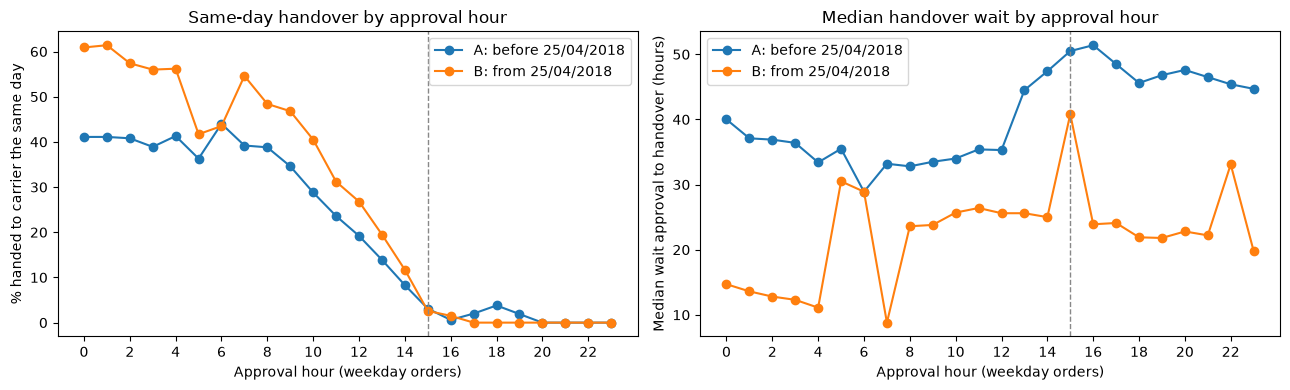

Effective cut-off approval hour: {'A: before 25/04/2018': 15, 'B: from 25/04/2018': 15}


In [40]:
order_df["handoff_wait_h"] = (
    order_df["order_delivered_carrier_date"] - order_df["order_approved_at"]
).dt.total_seconds() / 3600
order_df["same_day_handoff"] = (
    order_df["order_delivered_carrier_date"].dt.normalize() == order_df["order_approved_at"].dt.normalize()
)

wk = order_df[order_df["day_type"] == "Weekday"].copy()

same_day_tbl = (
    wk.pivot_table(index="approve_hour", columns="carrier_ts_regime", values="same_day_handoff", aggfunc="mean") * 100
).round(1)
median_wait_tbl = wk.pivot_table(
    index="approve_hour", columns="carrier_ts_regime", values="handoff_wait_h", aggfunc="median"
).round(1)

SAME_DAY_FLOOR_PCT = 5
cutoff_hour = {
    regime: int(same_day_tbl.index[(same_day_tbl.index >= 12) & (same_day_tbl[regime] < SAME_DAY_FLOOR_PCT)][0])
    for regime in same_day_tbl.columns
}

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for regime in same_day_tbl.columns:
    axes[0].plot(same_day_tbl.index, same_day_tbl[regime], marker="o", label=regime)
    axes[1].plot(median_wait_tbl.index, median_wait_tbl[regime], marker="o", label=regime)
for ax in axes:
    ax.axvline(min(cutoff_hour.values()), color="#888888", linestyle="--", linewidth=1)
    ax.set_xticks(range(0, 24, 2))
    ax.set_xlabel("Approval hour (weekday orders)")
    ax.legend()
axes[0].set_ylabel("% handed to carrier the same day")
axes[1].set_ylabel("Median wait approval to handover (hours)")
axes[0].set_title("Same-day handover by approval hour")
axes[1].set_title("Median handover wait by approval hour")
plt.tight_layout()
plt.show()

print("Effective cut-off approval hour:", cutoff_hour)

### Does missing the cut-off raise late risk?

Weekday orders approved at or after the cut-off hour (`missed_cutoff`) against those approved before it, within each regime, with a 95% Wilson interval and a chi-square test.

In [41]:
wk["missed_cutoff"] = wk["approve_hour"] >= wk["carrier_ts_regime"].map(cutoff_hour)

cutoff_effect = wk.groupby(["carrier_ts_regime", "missed_cutoff"]).agg(
    orders=("is_late", "size"),
    late=("is_late", "sum"),
    median_wait_h=("handoff_wait_h", "median"),
)
cutoff_effect["late_rate_pct"] = (cutoff_effect["late"] / cutoff_effect["orders"] * 100).round(2)
ci = [wilson_ci(r.late, r.orders) for r in cutoff_effect.itertuples()]
cutoff_effect["ci_low_pct"] = [round(c[0] * 100, 2) for c in ci]
cutoff_effect["ci_high_pct"] = [round(c[1] * 100, 2) for c in ci]
cutoff_effect["median_wait_h"] = cutoff_effect["median_wait_h"].round(1)
cutoff_effect.to_csv(TABLES_DIR / "step6_cutoff_effect.csv")
display(cutoff_effect)

rows = []
for regime, g in wk.groupby("carrier_ts_regime"):
    chi2, p, _, _ = chi2_contingency(pd.crosstab(g["missed_cutoff"], g["is_late"]), correction=False)
    rows.append({"regime": regime, "chi2": round(chi2, 2), "p_value": p})
pd.DataFrame(rows)

orders  late  median_wait_h  \
carrier_ts_regime    missed_cutoff                                
A: before 25/04/2018 False           30712  2349           35.3   
                     True            22549  1815           47.6   
B: from 25/04/2018   False           11677   561           24.6   
                     True             9595   456           24.1   

                                    late_rate_pct  ci_low_pct  ci_high_pct  
carrier_ts_regime    missed_cutoff                                          
A: before 25/04/2018 False                   7.65        7.36         7.95  
                     True                    8.05        7.70         8.41  
B: from 25/04/2018   False                   4.80        4.43         5.21  
                     True                    4.75        4.34         5.20

,regime,chi2,p_value
0,A: before 25/04/2018,2.90,0.088787
1,B: from 25/04/2018,0.03,0.860031


### Backlog: wait before handover

Backlog is measured as the wait between approval and carrier handover, in five bands. For each band: share of orders, late rate with a Wilson interval, and its share of all late orders.

In [42]:
BAND_EDGES = [0, 24, 48, 72, 120, np.inf]
BAND_LABELS = ["<=1 day", "1-2 days", "2-3 days", "3-5 days", ">5 days"]
order_df["wait_band"] = pd.cut(order_df["handoff_wait_h"], BAND_EDGES, labels=BAND_LABELS, include_lowest=True)


def band_table(df):
    g = df.groupby("wait_band", observed=True)["is_late"].agg(orders="size", late="sum")
    g["share_of_orders_pct"] = (g["orders"] / g["orders"].sum() * 100).round(1)
    g["late_rate_pct"] = (g["late"] / g["orders"] * 100).round(2)
    ci = [wilson_ci(r.late, r.orders) for r in g.itertuples()]
    g["ci_low_pct"] = [round(c[0] * 100, 2) for c in ci]
    g["ci_high_pct"] = [round(c[1] * 100, 2) for c in ci]
    g["share_of_late_orders_pct"] = (g["late"] / g["late"].sum() * 100).round(1)
    return g


band_tables = {"All orders": band_table(order_df)}
band_tables.update({regime: band_table(g) for regime, g in order_df.groupby("carrier_ts_regime")})
band_summary = pd.concat(band_tables, names=["group", "wait_band"])
band_summary.to_csv(TABLES_DIR / "step6_wait_band_late_rates.csv")
display(band_summary)

ct = pd.crosstab(order_df["wait_band"], order_df["is_late"])
chi2, p, dof, _ = chi2_contingency(ct, correction=False)
pd.DataFrame([{
    "chi2": round(chi2, 2), "dof": dof, "p_value": p,
    "cramers_v": round(np.sqrt(chi2 / (ct.to_numpy().sum() * (min(ct.shape) - 1))), 4),
}])

orders  late  share_of_orders_pct  \
group                wait_band                                      
All orders           <=1 day     27795  1074                 29.2   
                     1-2 days    22828  1278                 24.0   
                     2-3 days    14141   828                 14.9   
                     3-5 days    16360  1196                 17.2   
                     >5 days     13958  2133                 14.7   
A: before 25/04/2018 <=1 day     16643   800                 24.3   
                     1-2 days    17358  1100                 25.3   
                     2-3 days    10497   691                 15.3   
                     3-5 days    13210  1036                 19.3   
                     >5 days     10906  1684                 15.9   
B: from 25/04/2018   <=1 day     11152   274                 42.1   
                     1-2 days     5470   178                 20.7   
                     2-3 days     3644   137                 13.8   
                     3-5 days     3150   160                 11.9   
                     >5 days      3052   449                 11.5   

                                late_rate_pct  ci_low_pct  ci_high_pct  \
group                wait_band                                           
All orders           <=1 day             3.86        3.64         4.10   
                     1-2 days            5.60        5.31         5.90   
                     2-3 days            5.86        5.48         6.25   
                     3-5 days            7.31        6.92         7.72   
                     >5 days            15.28       14.69        15.89   
A: before 25/04/2018 <=1 day             4.81        4.49         5.14   
                     1-2 days            6.34        5.98         6.71   
                     2-3 days            6.58        6.12         7.07   
                     3-5 days            7.84        7.40         8.31   
                     >5 days            15.44       14.78        16.13   
B: from 25/04/2018   <=1 day             2.46        2.19         2.76   
                     1-2 days            3.25        2.82         3.76   
                     2-3 days            3.76        3.19         4.43   
                     3-5 days            5.08        4.37         5.90   
                     >5 days            14.71       13.50        16.01   

                                share_of_late_orders_pct  
group                wait_band                            
All orders           <=1 day                        16.5  
                     1-2 days                       19.6  
                     2-3 days                       12.7  
                     3-5 days                       18.4  
                     >5 days                        32.8  
A: before 25/04/2018 <=1 day                        15.1  
                     1-2 days                       20.7  
                     2-3 days                       13.0  
                     3-5 days                       19.5  
                     >5 days                        31.7  
B: from 25/04/2018   <=1 day                        22.9  
                     1-2 days                       14.9  
                     2-3 days                       11.4  
                     3-5 days                       13.4  
                     >5 days                        37.5

,chi2,dof,p_value,cramers_v
0,2028.11,4,0.0,0.146


### Late rate by handover wait

Bars start at zero. The dashed line is the overall late rate.

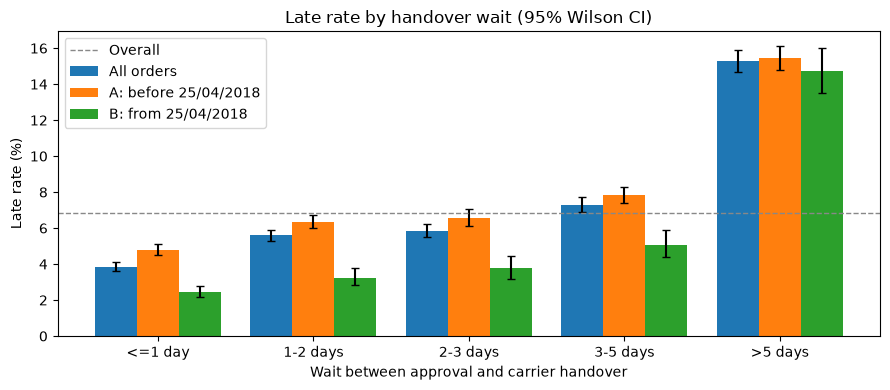

In [43]:
groups = ["All orders"] + list(hour_share.columns)
fig, ax = plt.subplots(figsize=(9, 4))
width = 0.27
for i, group in enumerate(groups):
    sub = band_summary.xs(group, level="group")
    err = [sub["late_rate_pct"] - sub["ci_low_pct"], sub["ci_high_pct"] - sub["late_rate_pct"]]
    ax.bar(np.arange(len(sub)) + (i - 1) * width, sub["late_rate_pct"], width, yerr=err, capsize=3, label=group)
ax.set_xticks(range(len(BAND_LABELS)))
ax.set_xticklabels(BAND_LABELS)
ax.axhline(order_df["is_late"].mean() * 100, color="#888888", linestyle="--", linewidth=1, label="Overall")
ax.set_xlabel("Wait between approval and carrier handover")
ax.set_ylabel("Late rate (%)")
ax.set_title("Late rate by handover wait (95% Wilson CI)")
ax.legend()
plt.tight_layout()
plt.show()